# Reward change-point design: ideal-observer optimal bounds

Design notebook for the RC (reward change) task in `task/RC/`. Solver: `pigeon.ideal_observer`.

## The task

Four 1000-step blocks, all at one difficulty: each of Petey's steps moves 0.01 toward the correct pile on
average, with SD 0.05 (MXSC's low SNR, 0.2). Each trial costs 1 step to start (as in MXSC), each error 15 extra steps,
and a trial with no response by step 50 times out with no coins.

| Block | Coins (correct / error) |
|---|---|
| Block 1: low reward (fixed) | +1 / −1 |
| Block 2: high reward (fixed) | +3 / −3 |
| Rising reward | +1 / −1, then +3 / −3 from the switch step on |
| Falling reward | +3 / −3, then +1 / −1 from the switch step on |

The switch step is the participant's median response time (in steps) in the two fixed blocks, pooled.
Each reward-change block is compared with the fixed block that has the same starting reward
(rising with Block 1, falling with Block 2).

## The ideal observer

Sees Petey's exact position, knows the difficulty but not the direction, and at each step either responds
(choosing the likelier pile) or waits. It maximizes coins per step, the right objective for a
step-budgeted block, by dynamic programming (`get_optimal_bounds`; see the module docstring). The optimal
bound at a step is the distance from the start beyond which responding beats waiting. It has no
non-decision time and no perceptual noise.

## Questions

1. What are the optimal bounds in each of the four blocks?
2. How much do they depend on the switch step, which differs across participants?
3. Which costs are needed? A charge per error, a charge to start each trial, or both: their effect on the
   optimal bound, on what is at stake in the reward-change blocks, and on the number of trials per block.
4. With participants who behave like the MXSC participants: trials per block, the power of the matched
   analysis of Figure 6 to detect each predicted change, and the bonus targets.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pigeon.data import get_data_table
from pigeon.ideal_observer import MAX_STEPS, evaluate_rc_bound, get_optimal_bounds, get_rc_policy_outcomes
from pigeon.path_defaults import DATA_DIR
from pigeon.plotting import FONT_RC, OPTIMAL_COLOR

LOW, HIGH = (1, 1), (3, 3)
BLOCKS = {  # name: (reward before the switch, reward after)
    'Block 1: low reward': (LOW, LOW),
    'Block 2: high reward': (HIGH, HIGH),
    'Rising reward': (LOW, HIGH),
    'Falling reward': (HIGH, LOW),
}
MATCHED = {'Rising reward': 'Block 1: low reward', 'Falling reward': 'Block 2: high reward'}
SWITCH = 9                          # the typical MXSC participant's switch step (median of B3 change points)
SWITCHES = (3, 6, 9, 13, 20, 25)    # MXSC range: quartiles 6 / 9 / 13, min 3, max 25
REFERENCE_GRAY = (0.55, 0.55, 0.55)

plt.rcParams.update({'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 12, 'xtick.labelsize': 12,
                     'ytick.labelsize': 12, 'axes.spines.top': False, 'axes.spines.right': False, **FONT_RC})

def plot_block_pair(ax, steps, matched_bound, change_bound, switch, matched_name, change_name, ymax=0.3,
                    label_never=True, legend=True):
    """Optimal bound of a reward-change block (red) over its matched fixed block's (gray dashed)."""
    ax.axvline(switch, color=(0.8, 0.8, 0.8), lw=1, zorder=0)
    ax.plot(steps, matched_bound, color=REFERENCE_GRAY, lw=2, ls='--', label=matched_name.split(':')[0] + ' (fixed)')
    ax.plot(steps, change_bound, color=OPTIMAL_COLOR, lw=2, label=change_name)
    never = np.isnan(change_bound)
    if never.any():   # waiting is optimal at every position: a bar along the top edge
        ax.plot(steps[never], np.full(never.sum(), ymax), color=OPTIMAL_COLOR, lw=5, solid_capstyle='butt',
                clip_on=False)
        if label_never:
            ax.text(switch + 1, ymax - 0.01, 'never respond', fontsize=8, color=OPTIMAL_COLOR, va='top')
    ax.set_xlim(0, MAX_STEPS)
    ax.set_ylim(0, ymax)
    if legend:
        ax.legend(loc='center right', fontsize=8, frameon=False)

## 1. Optimal bounds in the four blocks (switch at step 9)

Reward rate and the optimal bound at selected steps. "never" = waiting is optimal whatever Petey's
position.

In [2]:
res = {name: get_optimal_bounds(pre, post, SWITCH) for name, (pre, post) in BLOCKS.items()}
show = [1, 5, SWITCH - 1, SWITCH, 15, 30, 45]
table = pd.DataFrame({name: [1000 * rho] + list(b[show]) for name, (rho, b) in res.items()},
                     index=['coins per 1000 steps'] + [f'bound at step {s}' for s in show]).T
print(table.round(3).fillna('never').to_string())

                      coins per 1000 steps bound at step 1 bound at step 5 bound at step 8  bound at step 9  bound at step 15  bound at step 30  bound at step 45
Block 1: low reward                 42.129           0.112           0.112           0.112            0.112             0.112             0.112             0.098
Block 2: high reward               126.387           0.112           0.112           0.112            0.112             0.112             0.112             0.098
Rising reward                      112.364           never           never           never            0.122             0.122             0.122             0.102
Falling reward                     115.583           0.104           0.084           0.018            0.050             0.050             0.050             0.080


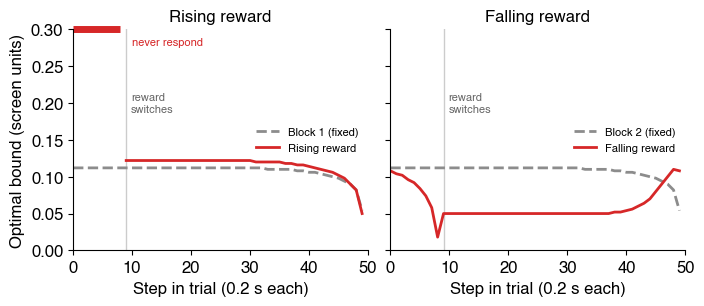

In [3]:
steps = np.arange(MAX_STEPS)
fig, axs = plt.subplots(1, 2, figsize=(17.6 / 2.54, 7.5 / 2.54), sharey=True, layout='constrained')
for ax, (change_name, matched_name) in zip(axs, MATCHED.items()):
    plot_block_pair(ax, steps, res[matched_name][1], res[change_name][1], SWITCH, matched_name, change_name)
    ax.text(SWITCH + 0.8, 0.2, 'reward\nswitches', fontsize=8, va='center', color=(0.4, 0.4, 0.4))
    ax.set_title(change_name)
    ax.set_xlabel('Step in trial (0.2 s each)')
axs[0].set_ylabel('Optimal bound (screen units)')
plt.show()

**What it shows**

- **Blocks 1 and 2 have identical optimal bounds**: flat at about 0.11, dropping near the 50-step timeout.
  Tripling both gain and loss triples the coins (42 vs 126 per 1000 steps) but cannot change which policy is
  best, so the two fixed blocks are normatively equivalent baselines.
- **Rising reward: never respond before the switch.** Waiting a few steps triples the payoff whatever Petey
  is doing. After the switch the bound is about 0.12, slightly above Block 1's.
- **Falling reward: respond sooner as the switch approaches.** The bound falls from about 0.11 to almost 0
  at the step before the switch (the last chance at 3 coins), then stays at about 0.05, well below Block 2's
  0.11: time is still valued at the high-reward rate (116 coins per 1000 steps) while each answer now pays
  1 coin. Near the timeout it rises, because with the error charge a weak guess loses coins on average.
- For scale: the ideal bound (0.11) is about half the fitted bound plateau of the MXSC participants at this
  difficulty (about 0.23); real participants also have a non-decision time and perceptual noise.

## 2. Dependence on the switch step

The switch step is each participant's own median response time, which varied from 3 to 25 steps in MXSC
(quartiles 6 / 9 / 13). Same layout as above, one row per switch step.

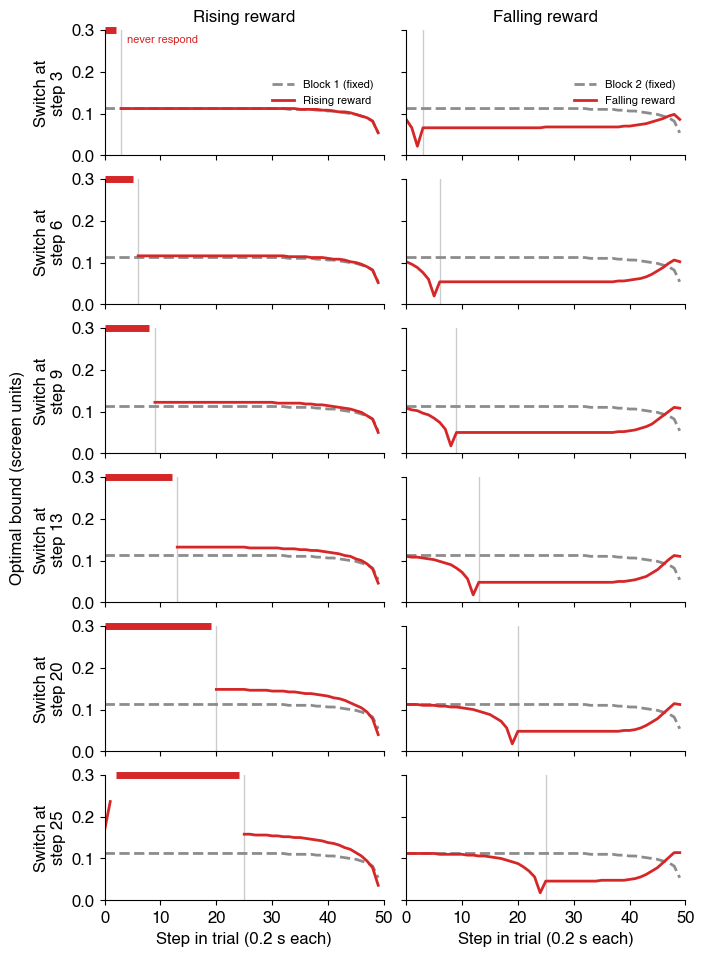

fixed blocks: bound 0.112
         block  switch step  coins per 1000 steps  steps of never-respond before the switch  bound at step before switch  median bound, 10 steps after switch
 Rising reward            3               125.565                                         3                          NaN                                0.112
Falling reward            3                80.162                                         0                        0.022                                0.066
 Rising reward            6               120.084                                         6                          NaN                                0.116
Falling reward            6               105.204                                         0                        0.020                                0.054
 Rising reward            9               112.364                                         9                          NaN                                0.122
Falling reward            

In [4]:
rows = []
fig, axs = plt.subplots(len(SWITCHES), 2, figsize=(17.6 / 2.54, 24 / 2.54), sharex=True, sharey=True,
                        layout='constrained')
for ri, sw in enumerate(SWITCHES):
    for ci, (change_name, matched_name) in enumerate(MATCHED.items()):
        rho, b = get_optimal_bounds(*BLOCKS[change_name], sw)
        plot_block_pair(axs[ri, ci], steps, res[matched_name][1], b, sw, matched_name, change_name,
                        label_never=(ri == 0), legend=(ri == 0))
        pre = b[1:sw]
        rows.append({'block': change_name, 'switch step': sw, 'coins per 1000 steps': 1000 * rho,
                     'steps of never-respond before the switch': int(np.isnan(b[:sw]).sum()),
                     'bound at step before switch': b[sw - 1],
                     'median bound, 10 steps after switch': np.nanmedian(b[sw:sw + 10])})
        if ri == 0:
            axs[ri, ci].set_title(change_name)
        if ci == 0:
            axs[ri, ci].set_ylabel(f'Switch at\nstep {sw}')
for ax in axs[-1]:
    ax.set_xlabel('Step in trial (0.2 s each)')
fig.supylabel('Optimal bound (screen units)', fontsize=12)
plt.show()
print(f"fixed blocks: bound {res['Block 1: low reward'][1][5]:.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

**What it shows**

- **The dynamics relative to the switch are the same at every switch step.** Rising reward: never respond
  before the switch, for switches as late as step 25; after it the bound is 0.11 (switch 3) to 0.16
  (switch 25). Falling reward: the bound stays at Block 2's level until about 10 steps before the switch,
  ramps to nearly 0 at the step before it, then settles at 0.045–0.065.
- So per-participant switch steps (the MXSC design) are fine, and keep about half of each participant's
  trials ending on each side of the switch.

**Implications for the analysis**

1. Align measures to the switch, not to the start of the trial: the falling-reward ramp covers about the last
   10 steps before the switch whatever the switch step, so a single tilt fit from step 1 dilutes it for
   participants with late switches. Participants with early switches (3–6 steps; about a quarter in MXSC)
   have a pre-switch window shorter than the ramp.
2. The rising-reward prediction needs no model: the fraction of responses before the switch, compared with
   the same steps in Block 1.
3. The falling-reward post-switch drop is a strong prediction, but few trials last past the switch once the
   pre-switch bound falls, so it will be hard to measure.

## 3. Which costs: a charge per error, a charge to start each trial, or both

Without extra charges (MXSC: 1 step to start, none per error) the reward-rate optimum at this difficulty is
to respond after one or two steps, so in the falling-reward block the ideal observer has already responded
before the switch and there is nothing to test. A charge makes waiting for evidence worthwhile. Each scheme
is compared on:

- **optimal bound**, **ideal accuracy** and **ideal trials per block** in a fixed block;
- **MXSC participants, trials per block**: each MXSC participant's block-1 mean RT and error rate (same
  difficulty) charged under the scheme, behavior held fixed (median across participants);
- **stake** (switch at step 9): the fraction of the reward rate lost by keeping the matched fixed block's
  optimal policy in the reward-change block (`evaluate_rc_bound`) instead of the change block's optimum.


In [5]:
SCHEMES = {  # name: (steps to start a trial, extra steps per error)
    'MXSC: no charges': (1, 0),
    'start charge 5': (5, 0),
    'start charge 10': (10, 0),
    'error charge 10': (1, 10),
    'error charge 15 (chosen)': (1, 15),
    'error charge 20': (1, 20),
    'both: 5 + 10 (first design)': (5, 10),
}

# MXSC block 1 (fixed, low SNR = the RC difficulty): each participant's mean RT (steps) and error rate.
mxsc = get_data_table(task_type='MXSC')
b1 = mxsc[mxsc['block_index'] == 1].groupby('subject_index')
human = pd.DataFrame({'rt': b1['RT'].mean(), 'p_error': b1['correct'].apply(lambda c: (c == 0).mean())})

rows = []
for name, (start, err) in SCHEMES.items():
    kw = {'start_cost': start, 'error_cost': err}
    rho, fixed = get_optimal_bounds(LOW, **kw)
    out = get_rc_policy_outcomes(fixed, **kw)
    row = {'scheme': name, 'optimal bound': np.nanmedian(fixed[1:30]), 'ideal accuracy': out['accuracy'],
           'ideal trials per block': out['trials_per_block'],
           'MXSC participants, trials per block': (1000 / (human['rt'] + start + err * human['p_error'])).median()}
    for block, (pre, post) in {'rising': (LOW, HIGH), 'falling': (HIGH, LOW)}.items():
        rho_c, _ = get_optimal_bounds(pre, post, SWITCH, **kw)
        # the matched fixed block's optimal policy, kept unchanged in the change block
        row[f'{block}: stake'] = 1 - evaluate_rc_bound(fixed, pre, post, SWITCH, **kw) / rho_c
    rows.append(row)
schemes = pd.DataFrame(rows).set_index('scheme')
print(f'MXSC block 1: {len(human)} participants')
print(schemes.round(3).to_string())


MXSC block 1: 65 participants
                             optimal bound  ideal accuracy  ideal trials per block  MXSC participants, trials per block  rising: stake  falling: stake
scheme                                                                                                                                                
MXSC: no charges                     0.028           0.616                 376.313                               74.074          0.385           0.000
start charge 5                       0.082           0.707                 102.022                               57.143          0.493           0.066
start charge 10                      0.122           0.768                  54.614                               44.444          0.382           0.170
error charge 10                      0.092           0.723                 106.630                               62.260          0.451           0.085
error charge 15 (chosen)             0.112           0.754      

## 4. Power, trial counts and bonus targets

Simulated by `scripts/run_rc_power.py` (see its docstring), for the chosen scheme and the first design.
Synthetic participants are MXSC participants' block-1 stopping-model fits (Figure 6, stage 1), drawn with
replacement into cohorts of 60, 20 cohorts per condition. In the fixed blocks each keeps the fitted bound;
in the reward-change blocks the log bound moves by a fraction **alpha** of the ideal observer's own
change-specific adjustment (relative to its fixed-block bound, projected onto the analysis's pre-switch
level and tilt and post-switch plateau). alpha = 0 is the null. Each cohort is analyzed with the matched
fit of Figure 6 (stage 2), its other parameters fixed at their true values, so the power is an upper bound.

- **level**: log pre-switch bound at the switch, change block minus matched fixed block (rising: positive);
- **tilt**: pre-switch slope of the log bound, change minus fixed (falling: negative);
- **step**: log(post / pre) at the switch, change minus fixed (rising: negative).

Detected = Wilcoxon signed-rank p < 0.05 across the cohort's participants. Bonus targets aim for about half
of participants reaching each one: the median coins per block at alpha = 0.25.


In [6]:
POWER_SCHEMES = {'s1_e15': 'error charge 15 (chosen)', 's5_e10': 'both: 5 + 10 (first design)'}
EFFECTS = [f'{block}_{effect}' for block in ('LH', 'HL') for effect in ('level', 'tilt', 'step')]
power, blocks = [], []
for tag, name in POWER_SCHEMES.items():
    f = DATA_DIR / f'rc_power_{tag}.pkl'
    if f.exists():
        power.append(pd.read_pickle(f).assign(scheme=name))
        blocks.append(pd.read_pickle(DATA_DIR / f'rc_blocks_{tag}.pkl').assign(scheme=name))
power, blocks = pd.concat(power), pd.concat(blocks)

# Fraction of cohorts with p < 0.05 (two-sided), and the median effect across cohorts
detected = power.groupby(['scheme', 'alpha'])[[f'{e}_p' for e in EFFECTS]].agg(lambda p: (p < 0.05).mean())
detected.columns = EFFECTS
size = power.groupby(['scheme', 'alpha'])[[f'{e}_median' for e in EFFECTS]].median()
size.columns = EFFECTS
print('Fraction of cohorts detecting each effect (LH = rising, HL = falling):')
print(detected.round(2).to_string())
print('\nMedian effect (log units; tilt per step):')
print(size.round(3).to_string())
print('\nCohorts per cell:', power.groupby(['scheme', 'alpha']).size().to_dict())
print('Participants excluded per cohort (edge fits), median:', power.groupby('scheme')['n_excluded'].median().to_dict())

# Trials per block and those left for the fit (trials 1-9 dropped), medians across participants
print('\nTrials per block (median [IQR]); trials in the fit:')
q = blocks.groupby(['scheme', 'alpha', 'block'])
trials = q['n_trials'].quantile([0.25, 0.5, 0.75]).unstack()
trials['fit'] = q['n_fit'].median()
print(trials.round(0).to_string())

# Bonus targets: about half of participants should reach each block's target. Median coins at alpha = 0.25.
coins = blocks[blocks['alpha'] == 0.25].groupby(['scheme', 'block'])['coins'].quantile([0.25, 0.5, 0.75]).unstack()
coins['suggested target'] = (5 * np.round(coins[0.5] / 5)).astype(int)
print('\nCoins per block at alpha = 0.25 (quartiles) and the target nearest the median (multiple of 5):')
print(coins.to_string())


Fraction of cohorts detecting each effect (LH = rising, HL = falling):
                                   LH_level  LH_tilt  LH_step  HL_level  HL_tilt  HL_step
scheme                      alpha                                                        
both: 5 + 10 (first design) 0.00        0.0     0.05     0.05       0.0     0.00     0.00
                            0.25        1.0     0.10     1.00       1.0     0.90     0.00
                            0.50        1.0     0.15     1.00       1.0     1.00     0.05
error charge 15 (chosen)    0.00        0.1     0.05     0.10       0.0     0.05     0.05
                            0.25        1.0     0.10     1.00       1.0     0.95     0.00
                            0.50        1.0     0.25     1.00       1.0     1.00     0.00

Median effect (log units; tilt per step):
                                   LH_level  LH_tilt  LH_step  HL_level  HL_tilt  HL_step
scheme                      alpha                                           